# Tarification automobile – freMTPL2
Objectif : construire une prime pure auto (fréquence × coût moyen) avec des GLM, à partir des données freMTPL2, puis l'intégrer à une app Streamlit.

## Journal
- 13/11/2026 : chargement des données et première exploration

##**Étape 1 - Importer les packages**

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.datasets import fetch_openml
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


##**Étape 2 – Chargement des données**

In [18]:
import os
dossier = '/content/drive/MyDrive/Tarification_Auto'
os.makedirs(dossier, exist_ok=True)

freq = fetch_openml(data_id=41214, as_frame=True).frame
sev = fetch_openml(data_id=41215, as_frame=True).frame

freq.to_csv(f'{dossier}/freq.csv', index=False)
sev.to_csv(f'{dossier}/sev.csv', index=False)

print(freq.shape, sev.shape)

(678013, 12) (26639, 2)


##**Étape 3 – Découverte des variables**

In [19]:
display(freq.head())
display(sev.head())
freq.info()
sev.info()

,IDpol,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region
0,1.0,1,0.10,D,5,0,55,50,B12,'Regular',1217,R82
1,3.0,1,0.77,D,5,0,55,50,B12,'Regular',1217,R82
2,5.0,1,0.75,B,6,2,52,50,B12,'Diesel',54,R22
3,10.0,1,0.09,B,7,0,46,50,B12,'Diesel',76,R72
4,11.0,1,0.84,B,7,0,46,50,B12,'Diesel',76,R72


,IDpol,ClaimAmount
0,1552,995.20
1,1010996,1128.12
2,4024277,1851.11
3,4007252,1204.00
4,4046424,1204.00


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 678013 entries, 0 to 678012
Data columns (total 12 columns):
 #   Column      Non-Null Count   Dtype   
---  ------      --------------   -----   
 0   IDpol       678013 non-null  float64 
 1   ClaimNb     678013 non-null  int64   
 2   Exposure    678013 non-null  float64 
 3   Area        678013 non-null  category
 4   VehPower    678013 non-null  int64   
 5   VehAge      678013 non-null  int64   
 6   DrivAge     678013 non-null  int64   
 7   BonusMalus  678013 non-null  int64   
 8   VehBrand    678013 non-null  category
 9   VehGas      678013 non-null  object  
 10  Density     678013 non-null  int64   
 11  Region      678013 non-null  category
dtypes: category(3), float64(2), int64(6), object(1)
memory usage: 48.5+ MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26639 entries, 0 to 26638
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   IDpol        2

###**Rappel de la signification des noms des variables**

**IDpol**: le numéro du contrat, qui fait le lien avec la base des sinistres.

**ClaimNb** : le nombre de sinistres, c’est ce qu’on veut prédire pour la fréquence.

**Exposure** : la durée de couverture en années, par exemple 0,5 pour six mois.

**Area et Region** : la zone et la région du conducteur.

**VehPower, VehAge, VehBrand, VehGas** : la puissance, l’âge, la marque et le carburant du véhicule.

**DrivAge** : l’âge du conducteur.

**BonusMalus** : le coefficient de bonus-malus.

**Density** : la densité de population de la commune.

**ClaimAmount, dans la base des sinistres** : le coût de chaque sinistre.

##**Étape 4 – Nettoyage des formats**

In [20]:
freq['IDpol'] = freq['IDpol'].astype(int)
freq['VehGas'] = freq['VehGas'].str.strip("'").astype('category')

print(freq['VehGas'].value_counts())
print(sev['IDpol'].isin(freq['IDpol']).value_counts())

VehGas
Regular    345877
Diesel     332136
Name: count, dtype: int64
IDpol
True     26444
False      195
Name: count, dtype: int64


##**Étape 5 - Fusion des bases**

In [21]:
sev_contrat = sev.groupby('IDpol')['ClaimAmount'].sum().reset_index()

base = freq.merge(sev_contrat, on='IDpol', how='left')
base['ClaimAmount'] = base['ClaimAmount'].fillna(0)

print(base.shape)
print(base['ClaimAmount'].sum())

(678013, 13)
59909216.5


Le code suivant compte les contrats qui déclarent des sinistres mais n’ont aucun montant. Si elle affiche 0, mon merge est cohérent.

In [22]:
print(((base['ClaimNb'] > 0) & (base['ClaimAmount'] == 0)).sum())

9116


Vérification des anomalies

In [23]:
# 1. Observer l'anomalie
anomalies = base[(base['ClaimNb'] > 0) & (base['ClaimAmount'] == 0)]
display(anomalies.head(10))
print(anomalies['ClaimNb'].value_counts())

# 2. Recalculer ClaimNb depuis la base sinistres
nb_sev = sev.groupby('IDpol').size().rename('ClaimNb_sev')
base = base.merge(nb_sev, on='IDpol', how='left')
base['ClaimNb_sev'] = base['ClaimNb_sev'].fillna(0).astype(int)
print((base['ClaimNb'] != base['ClaimNb_sev']).sum())

,IDpol,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region,ClaimAmount
0,1,1,0.10,D,5,0,55,50,B12,Regular,1217,R82,0.0
1,3,1,0.77,D,5,0,55,50,B12,Regular,1217,R82,0.0
2,5,1,0.75,B,6,2,52,50,B12,Diesel,54,R22,0.0
3,10,1,0.09,B,7,0,46,50,B12,Diesel,76,R72,0.0
4,11,1,0.84,B,7,0,46,50,B12,Diesel,76,R72,0.0
5,13,1,0.52,E,6,2,38,50,B12,Regular,3003,R31,0.0
6,15,1,0.45,E,6,2,38,50,B12,Regular,3003,R31,0.0
7,17,1,0.27,C,7,0,33,68,B12,Diesel,137,R91,0.0
8,18,1,0.71,C,7,0,33,68,B12,Diesel,137,R91,0.0
9,21,1,0.15,B,7,0,41,50,B12,Diesel,60,R52,0.0


ClaimNb
1     8608
2      485
3       20
4        2
11       1
Name: count, dtype: int64
9117


**Correction de ClaimNb à partir de la base sinistres**

**Hypothèse** : chaque ligne de la base sinistres = un sinistre distinct.

**Limite** : une ligne pourrait aussi être un paiement complémentaire sur un même sinistre (non identifiable ici).
Correction : ClaimNb recalculé depuis la base sinistres (9 116 contrats passés à 0 sinistre).

In [24]:
base['ClaimNb'] = base['ClaimNb_sev']
base = base.drop(columns='ClaimNb_sev')
print(base['ClaimNb'].sum(), base['ClaimAmount'].sum())

26444 59909216.5


##**Étape 6 – Indicateurs globaux**

In [25]:
freq_globale = base['ClaimNb'].sum() / base['Exposure'].sum()
cout_moyen = base['ClaimAmount'].sum() / base['ClaimNb'].sum()
prime_pure = base['ClaimAmount'].sum() / base['Exposure'].sum()

print(f"Fréquence : {freq_globale:.4f}")
print(f"Coût moyen : {cout_moyen:.0f} €")
print(f"Prime pure : {prime_pure:.0f} €")

Fréquence : 0.0738
Coût moyen : 2266 €
Prime pure : 167 €


### Formules utilisées
- Fréquence : $F = \dfrac{\sum \text{ClaimNb}}{\sum \text{Exposure}}$
- Coût moyen : $C = \dfrac{\sum \text{ClaimAmount}}{\sum \text{ClaimNb}}$
- Prime pure : $P = F \times C = \dfrac{\sum \text{ClaimAmount}}{\sum \text{Exposure}}$

### Lecture
- Environ 7,4 sinistres pour 100 assurés par an.
- Un sinistre coûte en moyenne 2 266 €.
- Un assuré coûte en moyenne 167 € par an, hors frais et marge.

Lien vers les formules utilisées : https://bookdown.org/boucherjphilippe/ACT5400/rappels-de-notions-de-tarification.html

##**Étape 7 – Fréquence par variable**

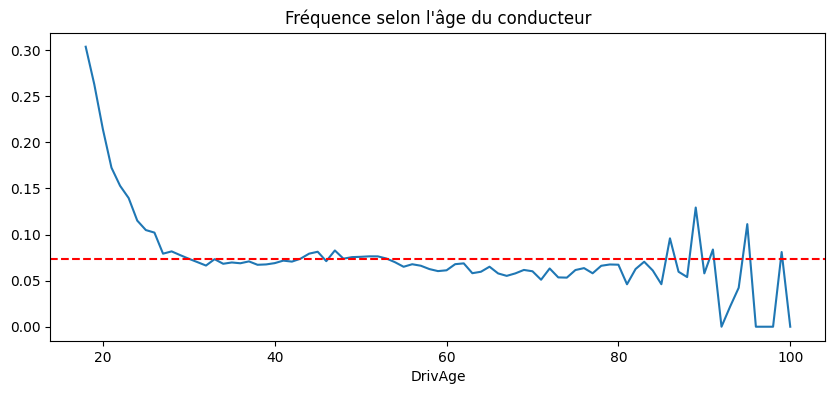

In [26]:
def freq_par(var):
    t = base.groupby(var, observed=True).agg(
        contrats=('IDpol', 'count'),
        sinistres=('ClaimNb', 'sum'),
        exposition=('Exposure', 'sum'))
    t['frequence'] = t['sinistres'] / t['exposition']
    return t

t = freq_par('DrivAge')
t['frequence'].plot(figsize=(10, 4), title="Fréquence selon l'âge du conducteur")
plt.axhline(freq_globale, color='red', linestyle='--')
plt.show()

### **Pourquoi ce graphique ?**
Avant de modéliser, on vérifie quelles variables font vraiment varier le risque. Ici, on croise l'âge du conducteur avec la fréquence de sinistres. Le trait rouge représente la fréquence moyenne du portefeuille (0,0738) : au-dessus, le groupe est plus risqué que la moyenne ; en dessous, moins risqué.

### **Ce qu'on retient**
- L'âge impacte clairement la sinistralité : les jeunes conducteurs (18-25 ans) ont une fréquence très élevée (jusqu'à 4 fois la moyenne à 18 ans), qui baisse rapidement jusqu'à 30 ans environ, puis se stabilise.
- Après 85 ans, les fluctuations viennent du faible nombre d'assurés, pas d'un vrai effet.
- On créera donc des tranches d'âge : pour regrouper les âges au risque proche, et pour fiabiliser les âges peu représentés.

Graphs pour les autres variables :

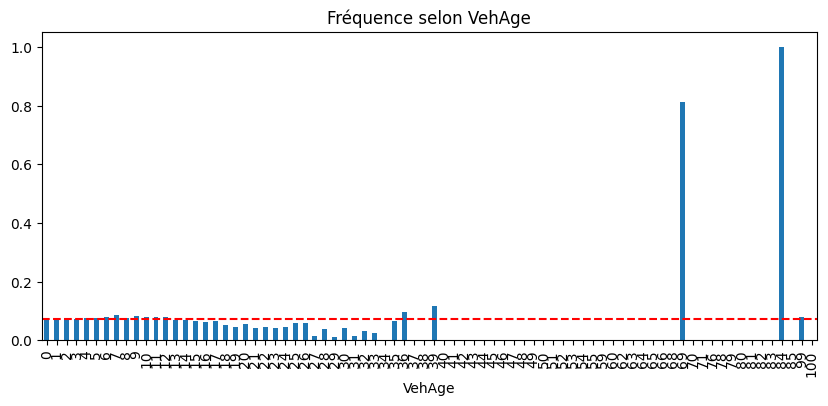

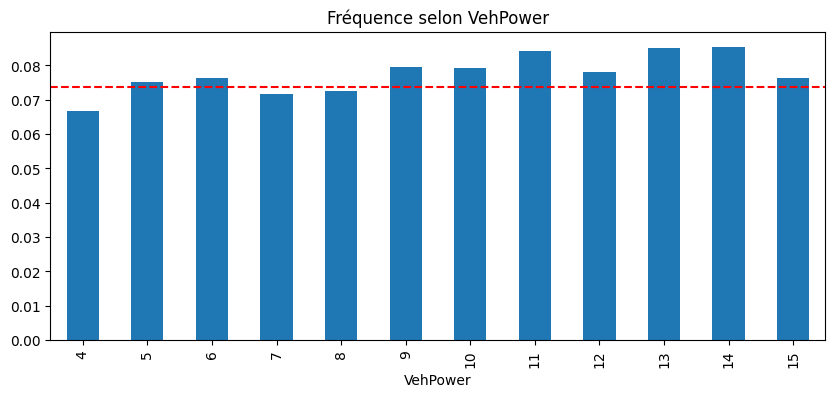

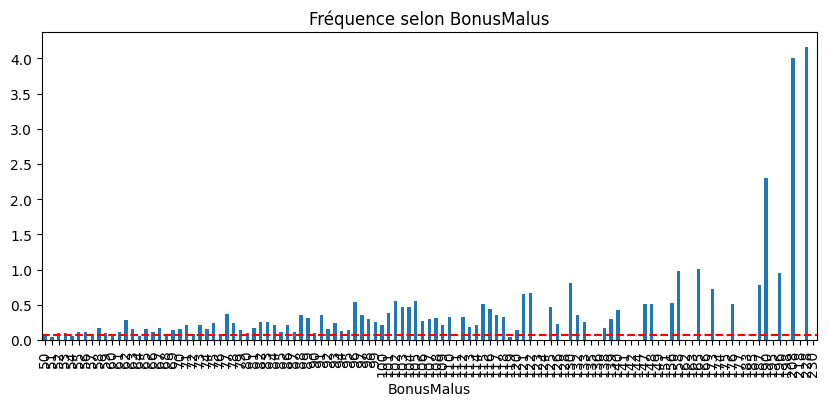

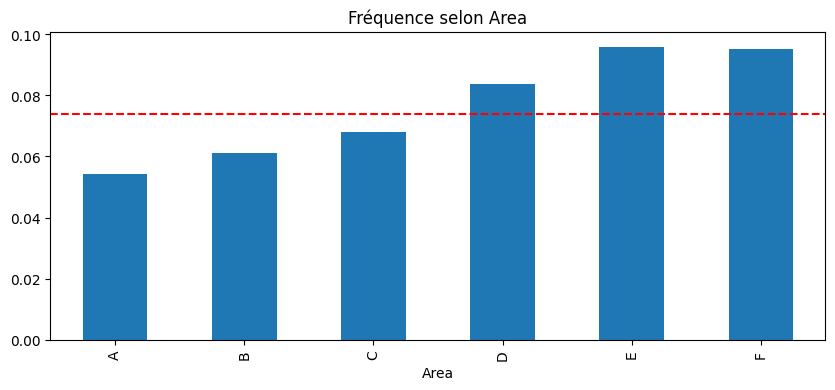

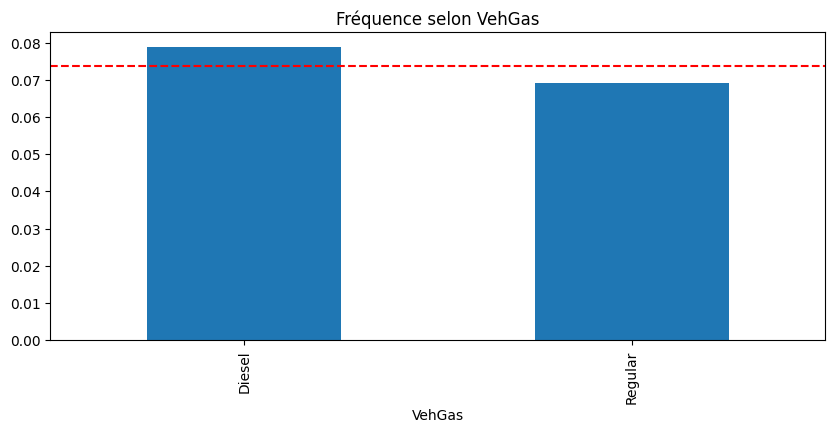

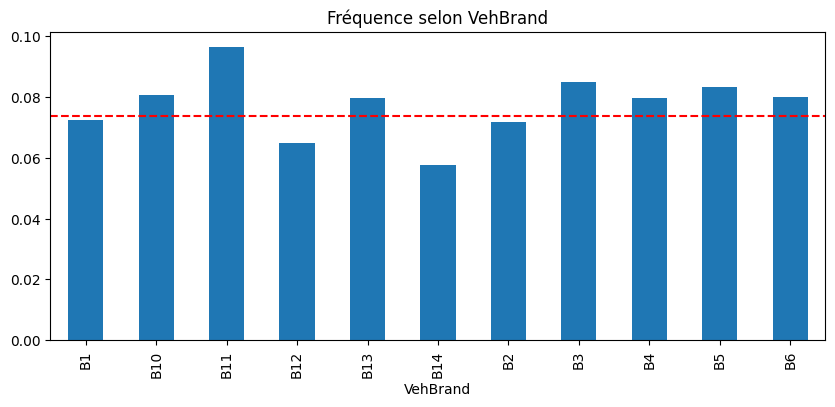

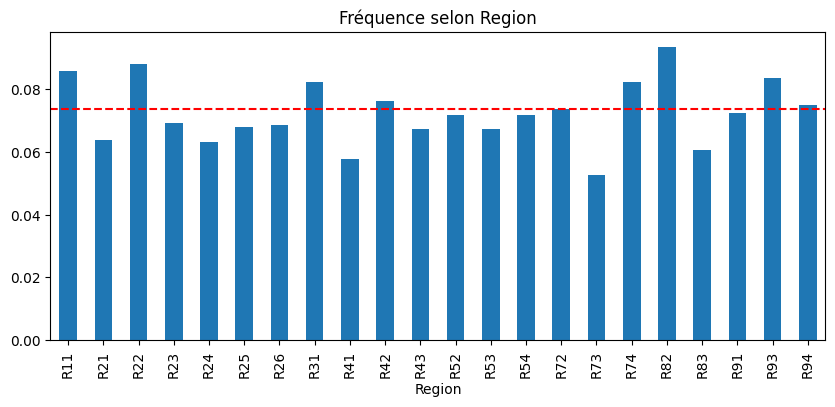

In [27]:
for var in ['VehAge', 'VehPower', 'BonusMalus', 'Area', 'VehGas', 'VehBrand', 'Region']:
    t = freq_par(var)
    t['frequence'].plot(kind='bar', figsize=(10, 4), title=f"Fréquence selon {var}")
    plt.axhline(freq_globale, color='red', linestyle='--')
    plt.show()

### VehAge – ce qu'on retient
- Fréquence stable entre 0 et ~12 ans, puis en baisse pour les véhicules plus anciens (ils roulent probablement moins).
- Les pics après 35 ans viennent d'un ou deux contrats seulement : ce n'est pas un vrai effet.
- On regroupera en tranches et on fusionnera les véhicules très anciens.

### VehPower – ce qu'on retient
- Effet faible : légère hausse de la fréquence avec la puissance (0,067 pour la puissance 4, ~0,085 pour 13-14).
- On le garde, en regroupant les puissances proches ; le GLM dira si l'effet est significatif.

### BonusMalus – ce qu'on retient
- Forte relation : plus le coefficient est élevé, plus la fréquence est élevée (les pics extrêmes = très peu de contrats).
- En France, le CRM est légal et connu à la souscription (relevé d'information), mais il résume l'historique : c'est une information a posteriori.
- Choix : on l'exclut du GLM a priori pour éviter de pénaliser deux fois ; il sera appliqué ensuite comme coefficient multiplicateur (partie 2).

### Area – ce qu'on retient
- Area = classe de densité de la commune (A rural → F très urbain).
- Effet clair et régulier : la fréquence passe de ~0,054 (A) à ~0,095 (E-F), presque x2.
- Area et Density mesurent la même chose : on choisira l'une des deux au moment du zonier.

### VehGas, VehBrand, Region – ce qu'on retient
- VehGas : diesel ~0,079 vs essence ~0,069. Effet modéré (hypothèse : les diesels roulent plus).
- VehBrand : écarts entre marques (B11 haute, B12/B14 basses) ; à vérifier avec le nombre de contrats.
- Region : fréquence de ~0,053 (R73 Midi-Pyrénées) à ~0,093 (R82 Rhône-Alpes) → base du zonier.



## 4. Le récapitulatif à retenir

| Variable | Effet sur la fréquence | Décision |
|---|---|---|
| DrivAge | Fort : jeunes ×4 | ✅ GLM, en tranches |
| Area | Fort et régulier : A → F, ×1,8 | ✅ GLM ou zonier |
| Region | Moyen | ✅ Zonier |
| VehAge | Modéré : baisse après 12-15 ans | ✅ GLM, en tranches |
| VehGas | Modéré : diesel > essence | ✅ GLM |
| VehBrand | Modéré, à vérifier | ✅ GLM, en regroupant |
| VehPower | Faible | ✅ GLM, le modèle tranchera |
| BonusMalus | Très fort | ❌ Hors GLM, appliqué ensuite (partie 2) |
| Density | Pas encore regardé | Prochaine étape |






**La règle d'or à retenir : une fréquence se lit toujours avec son exposition.**


Un pic sur un graphique de fréquence ne veut rien dire tant qu’on ne sait pas combien d’assurés il y a derrière

### Vérification : exposition derrière les pics de VehAge
- Le pic à 84 ans = 1 sinistre sur 1 an d'exposition (un seul contrat) → fréquence de 1,0 sans valeur statistique.
- De 71 à 85 ans : moins de 2 années d'exposition par âge → trop peu pour conclure.
- 99 et 100 ans : probablement des codes "âge inconnu" plutôt que de vrais véhicules.
- Règle retenue : toujours lire une fréquence avec son exposition. On regroupera les véhicules très anciens dans une seule classe (ex. "20 ans et plus").

In [28]:
t = freq_par('VehAge')
print(t.tail(12))

        contrats  sinistres  exposition  frequence
VehAge                                            
71             1          0    0.220000   0.000000
76             1          0    0.130000   0.000000
78             1          0    1.000000   0.000000
79             1          0    1.000000   0.000000
80             3          0    1.620000   0.000000
81             3          0    1.360000   0.000000
82             1          0    1.000000   0.000000
83             2          0    0.540000   0.000000
84             1          1    1.000000   1.000000
85             1          0    0.970000   0.000000
99            23          1   12.745464   0.078459
100           25          0   15.150000   0.000000


Je reprends tes questions une par une.

## 1. Les « ×4 » et « ×1,8 »

C'est simplement une **division** : la fréquence d'un groupe divisée par une autre fréquence. Ça dit combien de fois un groupe est plus risqué qu'un autre.

- **Âge, « ×4 »** : à 18 ans, la fréquence est d'environ 0,30, et la moyenne du portefeuille est de 0,074. 0,30 ÷ 0,074 ≈ **4**. Un conducteur de 18 ans a donc environ **4 fois plus** de sinistres que la moyenne.
- **Area, « ×1,8 »** : en zone F, la fréquence est d'environ 0,095, et en zone A d'environ 0,054. 0,095 ÷ 0,054 ≈ **1,8**. Un assuré en zone très urbaine a presque **2 fois plus** de sinistres qu'en zone rurale.

Dans le métier, ces rapports s'appellent des **relativités**. Le GLM en calculera une pour chaque variable, et le tarif final sera une multiplication de ces relativités.

## 2. Fort ou faible : sur quoi je me base

Sur l'**écart entre le groupe le plus risqué et le moins risqué**, en ne regardant que les groupes qui ont assez d'exposition :

| Variable | Écart (max ÷ min) | Jugement |
|---|---|---|
| DrivAge | ≈ ×4 | Très fort |
| Area | ≈ ×1,8 | Fort |
| VehPower | 0,085 ÷ 0,067 ≈ ×1,3 | Faible |



## 3. Region, Area et zonier

Ce sont **deux informations géographiques différentes** :
- **Area** dit *quel type de commune* : de A, rurale, à F, très urbaine.
- **Region** dit *où en France* : Île-de-France, Bretagne, etc.

Tu as raison, un zonier est une carte des zones. Mais en tarification, c'est surtout une **carte qui se transforme en coefficients**. On le construit en trois temps :
1. On calcule la fréquence ou la prime de chaque zone.
2. On regroupe les zones au risque proche en quelques classes, par exemple 5 classes, de la moins risquée à la plus risquée.
3. Chaque classe reçoit un coefficient, par exemple ×0,85 pour la classe 1 et ×1,25 pour la classe 5.

**Peut-on le faire ?** Oui, au niveau des 22 régions combinées avec la densité. Pas plus finement, parce qu'on n'a pas les codes postaux. Ça suffira pour une belle carte de France dans l'app.

## 4. La « partie 2 »

1. **A priori** : GLM, zonier, prime pure, prime commerciale.
2. **A posteriori** : bonus-malus et crédibilité. C'est là qu'on appliquera le CRM.
3. **Suivi du portefeuille** : S/P, fréquence, coût moyen.
4. **Défis du métier** : inflation, climat, machine learning…

##**Étape 8 – Densité**

                 contrats  sinistres    exposition  frequence
Density_tr                                                   
(-0.001, 3.497]     68910       2137  41630.172350   0.051333
(3.497, 4.205]      68430       2385  39778.837215   0.059957
(4.205, 4.804]      66925       2370  37363.992860   0.063430
(4.804, 5.366]      67253       2469  36740.386709   0.067201
(5.366, 5.974]      68699       2449  36502.539628   0.067091
(5.974, 6.574]      66699       2653  35538.591957   0.074651
(6.574, 7.18]       69809       3127  36512.094741   0.085643
(7.18, 7.907]       68036       2950  32974.109183   0.089464
(7.907, 8.326]      67824       3022  31813.647680   0.094991
(8.326, 10.204]     65428       2882  29645.073138   0.097217


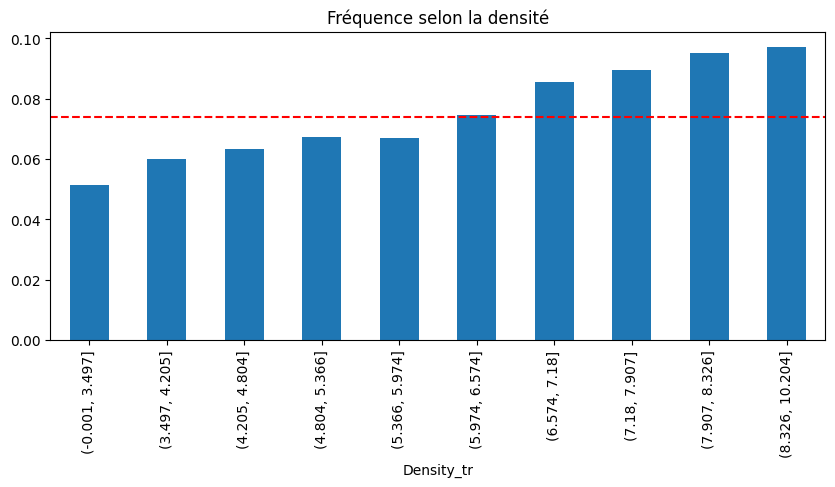

In [29]:
base['Density_tr'] = pd.qcut(np.log(base['Density']), 10)
t = freq_par('Density_tr')
print(t)
t['frequence'].plot(kind='bar', figsize=(10, 4), title="Fréquence selon la densité")
plt.axhline(freq_globale, color='red', linestyle='--')
plt.show()

### Étape 8 – Densité : ce qu'on retient
- Densité découpée en 10 tranches de même effectif (sur le logarithme, car elle va de 1 à ~27 000 hab/km²).
- Effet fort et parfaitement régulier : la fréquence passe de ~0,051 (communes rurales, < 33 hab/km²) à ~0,097 (communes très denses, > 4 100 hab/km²), soit ×1,9.
- Résultats fiables : ~67 000 contrats et > 30 000 années d'exposition par tranche.
- Area mesure la même chose (×1,8) mais moins finement → on privilégiera log(Density) dans le GLM pour ne pas compter l'effet deux fois.
- Remarque : exposition plus faible en zone dense (contrats plus courts ; hypothèse : plus de changements d'assureur ou de véhicule).

In [30]:
sup1 = base[base['Exposure'] > 1]
print(len(sup1))
print(sup1['Exposure'].describe())
display(sup1.head(10))

1224
count    1224.000000
mean        1.113840
std         0.159296
min         1.010000
25%         1.020000
50%         1.040000
75%         1.150000
max         2.010000
Name: Exposure, dtype: float64


,IDpol,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region,ClaimAmount,Density_tr
179652,1179653,0,1.99,A,11,10,50,50,B12,Regular,29,R25,0.00,"(-0.001, 3.497]"
179653,1179654,1,1.17,D,4,2,21,112,B6,Regular,721,R93,74.45,"(6.574, 7.18]"
179655,1179656,1,1.12,E,6,0,37,72,B4,Diesel,9307,R82,1313.72,"(8.326, 10.204]"
179657,1179658,0,1.48,D,7,4,46,50,B6,Diesel,776,R93,0.00,"(6.574, 7.18]"
179659,1179660,1,1.50,C,8,14,26,76,B1,Regular,372,R25,518.48,"(5.366, 5.974]"
179660,1179661,0,1.53,A,8,16,31,68,B1,Diesel,10,R24,0.00,"(-0.001, 3.497]"
179661,1179662,0,1.48,F,5,1,72,50,B14,Regular,27000,R11,0.00,"(8.326, 10.204]"
179662,1179663,0,1.01,B,6,0,24,72,B3,Diesel,93,R91,0.00,"(4.205, 4.804]"
179665,1179666,0,1.03,C,7,4,52,57,B1,Diesel,443,R73,0.00,"(5.974, 6.574]"
179666,1179667,0,1.09,A,5,4,37,50,B4,Diesel,26,R24,0.00,"(-0.001, 3.497]"


### Vérification : expositions > 1 an
- 1 224 contrats concernés (0,2 % de la base), médiane 1,04, max 2,01.
- IDpol consécutifs → probablement un défaut d'extraction sur un bloc de contrats.
- La base couvre une année d'observation : une exposition > 1 n'a pas de sens.
- Décision : exposition plafonnée à 1 (impact ≈ 140 années d'exposition, soit ~0,04 % du total).

##**Étape 9 - GLM fréquence**

In [31]:
base['Exposure'] = base['Exposure'].clip(upper=1)
base['DrivAge_tr'] = pd.cut(base['DrivAge'], [17, 21, 25, 30, 45, 60, 75, 101])
base['VehAge_tr'] = pd.cut(base['VehAge'], [-1, 1, 5, 10, 15, 101])
base['VehPower_tr'] = base['VehPower'].clip(upper=9)
base['logDensity'] = np.log(base['Density'])

glm_freq = smf.glm(
    'ClaimNb ~ DrivAge_tr + VehAge_tr + C(VehPower_tr) + VehGas + VehBrand + Region + logDensity',
    data=base,
    family=sm.families.Poisson(),
    offset=np.log(base['Exposure'])
).fit()

print(glm_freq.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                ClaimNb   No. Observations:               678013
Model:                            GLM   Df Residuals:                   677964
Model Family:                 Poisson   Df Model:                           48
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -1.0969e+05
Date:                Sat, 14 Nov 2026   Deviance:                   1.6860e+05
Time:                        00:05:33   Pearson chi2:                 1.21e+06
No. Iterations:                     7   Pseudo R-squ. (CS):           0.004719
Covariance Type:            nonrobust                                         
                                                      coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------

Ton premier GLM a tourné. Avant de le lire ligne par ligne, voici les trois règles de lecture.

## Comment lire ce tableau

**Règle 1 : il y a un profil de référence.** Pour chaque variable, la première catégorie n'apparaît pas dans le tableau. C'est la **référence**, et toutes les autres lui sont comparées. Ici, le profil de référence est : conducteur de 18 à 21 ans, véhicule de 0 à 1 an, puissance 4, diesel, marque B1, région R11 (Île-de-France).

**Règle 2 : on prend l'exponentielle du coefficient.** La colonne `coef` est sur l'échelle du logarithme, à cause de la fonction de lien log du GLM. Pour la rendre lisible, on calcule **exp(coef)**, et on obtient la **relativité**, le fameux « ×… » :
- exp(coef) = 0,85 signifie 15 % de sinistres en moins que la référence ;
- exp(coef) = 1,20 signifie 20 % de sinistres en plus.

**Règle 3 : la colonne P>|z| dit si l'effet est fiable.** Si elle est **sous 0,05**, l'effet est statistiquement significatif. Au-dessus, l'écart avec la référence peut être dû au hasard.



## Ce que dit le modèle

| Variable | Résultat (exp(coef)) | Lecture simple |
|---|---|---|
| **Âge conducteur** | 21-25 ans : 0,57 · 30-45 ans : 0,32 · 60-75 ans : 0,29 | Un 18-21 ans a environ **3 fois plus** de sinistres qu'un 30-45 ans. C'est l'effet le plus fort, et tout est significatif |
| **Âge véhicule** | 15 ans et plus : 0,78 | Les vieux véhicules ont **22 % de sinistres en moins**. Entre 1 et 15 ans, les écarts sont faibles |
| **Puissance** | 9 et plus : 1,21 · 5 à 8 : 1,05-1,08 | Faible, sauf les puissances de 9 et plus, à **+21 %** |
| **Carburant** | Essence : 0,85 | L'essence a **15 % de sinistres en moins** que le diesel |
| **Marque** | B12 : 0,80 · B11 : 1,18 · B5 : 1,10 | Quelques marques se distinguent, beaucoup d'autres non (p > 0,05) |
| **Région** | R74 Limousin : 1,36 · R82 Rhône-Alpes : 1,18 · R73 Midi-Pyrénées : 0,78 | Des écarts réels, mais **beaucoup de régions ne sont pas significatives** |
| **log(Densité)** | 0,1026 | Quand la densité **double**, la fréquence augmente d'environ **7 %** (2^0,1026 ≈ 1,07) |


**Trois choses à remarquer :**

1. **Le modèle confirme ton exploration.** Âge, densité, carburant et vieux véhicules : on retrouve les tendances vues sur les graphiques. C'est bon signe.
2. **Les régions non significatives justifient le zonier.** Avec 22 régions, beaucoup ont trop peu de données pour un coefficient fiable. Regarde le Limousin (R74) : son écart-type de 0,075 est grand, donc son ×1,36 est incertain. On regroupera les régions en quelques classes.
3. **Le Pseudo R² très faible (0,005) est normal.** En assurance, le hasard domine : on ne peut pas prédire *qui* aura un accident, seulement *combien* en moyenne par profil. Ne t'inquiète pas si on te pose la question en entretien, c'est la bonne réponse.

In [32]:
#Calcule les relativités :

relativites = pd.DataFrame({
    'relativite': np.exp(glm_freq.params),
    'p_value': glm_freq.pvalues
}).round(3)
display(relativites)

,relativite,p_value
Intercept,0.121,0.000
"DrivAge_tr[T.Interval(21, 25, closed='right')]",0.568,0.000
"DrivAge_tr[T.Interval(25, 30, closed='right')]",0.362,0.000
"DrivAge_tr[T.Interval(30, 45, closed='right')]",0.322,0.000
"DrivAge_tr[T.Interval(45, 60, closed='right')]",0.329,0.000
"DrivAge_tr[T.Interval(60, 75, closed='right')]",0.288,0.000
"DrivAge_tr[T.Interval(75, 101, closed='right')]",0.317,0.000
"VehAge_tr[T.Interval(1, 5, closed='right')]",1.033,0.124
"VehAge_tr[T.Interval(5, 10, closed='right')]",1.064,0.005
"VehAge_tr[T.Interval(10, 15, closed='right')]",0.977,0.330


### Étape 9 – Lecture du premier GLM fréquence
- Profil de référence : 18-21 ans, véhicule 0-1 an, puissance 4, diesel, marque B1, région R11.
- Lecture : relativité = exp(coef) ; significatif si p-value < 0,05.
- Âge conducteur : effet le plus fort (18-21 ans ≈ 3 fois plus de sinistres que 30-45 ans).
- Véhicule 15 ans et plus : -22 % ; puissance 9 et plus : +21 % ; essence : -15 % vs diesel.
- Densité : +7 % de fréquence quand la densité double.
- Beaucoup de régions et de marques non significatives → regroupements à prévoir (zonier pour les régions).
- Pseudo R² faible = normal en assurance (le hasard individuel domine).

##**Étape 10 - Zonier**

In [33]:
coef_reg = glm_freq.params.filter(like='Region')
coef_reg.index = coef_reg.index.str.extract(r'(R\d+)')[0]
coef_reg['R11'] = 0
rel_reg = np.exp(coef_reg).sort_values()

expo_reg = base.groupby('Region', observed=True)['Exposure'].sum()
zonier = pd.DataFrame({'relativite': rel_reg, 'exposition': expo_reg}).sort_values('relativite')
display(zonier.round(3))

,relativite,exposition
R73,0.777,7014.429
R41,0.787,8112.488
R43,0.927,563.773
R25,0.928,6652.651
R53,0.928,27752.794
R83,0.940,2322.274
R24,0.945,102706.443
R23,0.953,3176.882
R52,0.976,21930.321
R42,0.981,1208.636


 À 0,78, Midi-Pyrénées a environ 22 % de sinistres en moins que l'Île-de-France, et le Limousin, à 1,36, environ 36 % de plus. Mais regarde aussi l'exposition : R43, R42, R21, R94 ou R74 en ont moins de 2 500, donc leur relativité est fragile. Le regroupement sert justement à leur éviter un coefficient qui ne repose que sur eux.


 **DECOUPAGE**

 Entre 0,79 et 0,93, il y a un grand écart, d’où la coupure entre les zones 1 et 2. Entre 1,05 et 1,10, il y a un autre saut, d’où la zone 4. Ensuite, chaque zone doit avoir assez d’exposition pour que son coefficient soit fiable

In [34]:
zones = {
    'Z1': ['R73', 'R41'],
    'Z2': ['R43', 'R25', 'R53', 'R83', 'R24', 'R23', 'R52', 'R42'],
    'Z3': ['R11', 'R21', 'R31', 'R72', 'R54', 'R26', 'R91'],
    'Z4': ['R93', 'R82', 'R22', 'R94', 'R74']
}
map_zone = {r: z for z, regs in zones.items() for r in regs}
base['Zone'] = base['Region'].astype(str).map(map_zone)
print(base.groupby('Zone')['Exposure'].sum().round(0))

Zone
Z1     15127.0
Z2    166314.0
Z3     88103.0
Z4     88816.0
Name: Exposure, dtype: float64


**On relance le GLM en remplaçant les 22 régions par nos 4 zones**

In [35]:
glm_freq2 = smf.glm(
    'ClaimNb ~ DrivAge_tr + VehAge_tr + C(VehPower_tr) + VehGas + VehBrand + C(Zone, Treatment("Z3")) + logDensity',
    data=base,
    family=sm.families.Poisson(),
    offset=np.log(base['Exposure'])
).fit()

print(np.exp(glm_freq2.params.filter(like='Zone')).round(3))
print('AIC ancien :', round(glm_freq.aic), ' AIC nouveau :', round(glm_freq2.aic))

C(Zone, Treatment("Z3"))[T.Z1]    0.766
C(Zone, Treatment("Z3"))[T.Z2]    0.922
C(Zone, Treatment("Z3"))[T.Z4]    1.130
dtype: float64
AIC ancien : 219471  AIC nouveau : 219455


C’est le même modèle, mais avec la zone à la place de la région. On prend la zone 3 comme référence, puisque c’est celle qui contient l’Île-de-France. Le code affiche ensuite les relativités des zones, puis compare les deux modèles avec l’AIC, un score où plus c’est bas, mieux c’est. Il récompense un modèle qui colle aux données, mais pénalise celui qui a trop de paramètres. On verra si nos 4 zones font aussi bien que les 22 régions, avec beaucoup moins de coefficients.




---


Très bon résultat. Par rapport à la zone 3, la zone 1 a environ 23 % de sinistres en moins, la zone 2 environ 8 % en moins, et la zone 4 environ 13 % en plus. Les quatre classes sont donc bien ordonnées, du moins risqué au plus risqué.

Et l'AIC passe de 219 471 à 219 455 : il baisse un peu, alors qu'on est passées de 21 coefficients de région à seulement 3. Le modèle est donc plus simple, et légèrement meilleur. C'est exactement ce qu'on cherche, et c'est un argument solide à présenter en entretien.


### Étape 10 – Zonier
- 22 régions regroupées en 4 zones selon leurs relativités GLM (Z1 la moins risquée → Z4 la plus risquée).
- Relativités vs Z3 : Z1 0,77 ; Z2 0,92 ; Z4 1,13.
- AIC : 219 471 (22 régions) → 219 455 (4 zones) : modèle plus simple et légèrement meilleur.
- Limite : découpage à l'œil ; une méthode statistique (k-means pondéré) pourrait l'affiner.

##**Étape 11 – Validation**

/tmp/ipykernel_494/2806517175.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  val = base.groupby('decile').apply(lambda g: pd.Series({


,predite,observee
decile,,
1,0.0425,0.0420
2,0.0518,0.0527
3,0.0575,0.0567
4,0.0626,0.0638
5,0.0675,0.0667
6,0.0730,0.0708
7,0.0793,0.0788
8,0.0873,0.0889
9,0.0988,0.1020


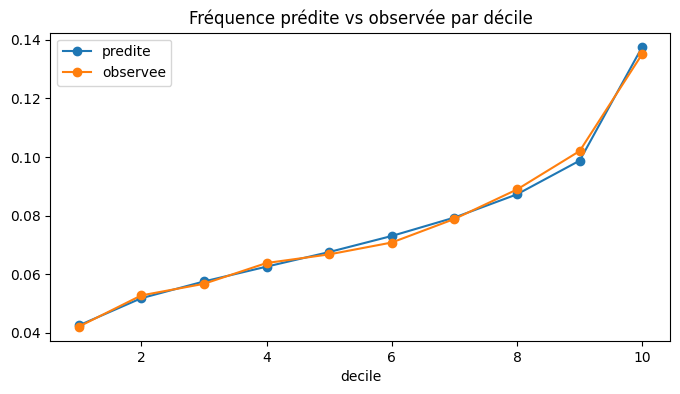

In [36]:
base['freq_pred'] = glm_freq2.predict(base, offset=np.log(base['Exposure'])) / base['Exposure']
base['decile'] = pd.qcut(base['freq_pred'], 10, labels=False) + 1

val = base.groupby('decile').apply(lambda g: pd.Series({
    'predite': (g['freq_pred'] * g['Exposure']).sum() / g['Exposure'].sum(),
    'observee': g['ClaimNb'].sum() / g['Exposure'].sum()
}))
display(val.round(4))
val.plot(marker='o', figsize=(8, 4), title="Fréquence prédite vs observée par décile")
plt.show()

### **Étape 11 – Validation par déciles**
- Assurés classés en 10 groupes selon la fréquence prédite.
- Prédite et observée quasi identiques dans chaque groupe → modèle bien calibré.
- Fréquence de ~0,042 (décile 1) à ~0,135 (décile 10), soit ×3,2 → bon pouvoir de segmentation.
- Limite : validation sur les données d'apprentissage ; à refaire sur un échantillon test.

##**Étape 12 – Gros sinistres**

In [37]:
montants = sev[sev['IDpol'].isin(base['IDpol'])]['ClaimAmount']
print(montants.describe(percentiles=[.5, .9, .99, .995, .999]).round(0))

for seuil in [10000, 20000, 50000, 100000]:
    exces = (montants - seuil).clip(lower=0).sum()
    print(seuil, '€ :', (montants > seuil).sum(), 'sinistres,', round(exces / montants.sum() * 100, 1), '% de la charge au-dessus du seuil')

count      26444.0
mean        2266.0
std        29371.0
min            1.0
50%         1172.0
90%         2768.0
99%        16451.0
99.5%      34377.0
99.9%     152223.0
max      4075401.0
Name: ClaimAmount, dtype: float64
10000 € : 478 sinistres, 34.5 % de la charge au-dessus du seuil
20000 € : 215 sinistres, 29.3 % de la charge au-dessus du seuil
50000 € : 88 sinistres, 22.6 % de la charge au-dessus du seuil
100000 € : 41 sinistres, 17.7 % de la charge au-dessus du seuil


### Étape 12 - Écrêtement des gros sinistres
**texte en gras**
- **Sinistre médian** : **1 172 €** ; **coût moyen** : **2 266 €**, tiré vers le haut par quelques montants extrêmes (max ≈ 4,1 M€).
- **Écrêtement** : chaque sinistre est plafonné à un seuil ; l'excédent est réparti sur tous les assurés (mutualisation).
- **Seuil retenu** : 20 000 € (≈ 99e centile) → 215 sinistres concernés (< 1 %), 29,3 % de la charge mutualisée.
- **Raison** : les gros sinistres sont rares et imprévisibles ; sans écrêtement, ils déformeraient le modèle de coût.

In [38]:
seuil = 20000
sev_ok = sev[sev['IDpol'].isin(base['IDpol'])].copy()
sev_ok['Montant_ecrete'] = sev_ok['ClaimAmount'].clip(upper=seuil)

coef_surcharge = sev_ok['ClaimAmount'].sum() / sev_ok['Montant_ecrete'].sum()
print('Coefficient de surcharge :', round(coef_surcharge, 3))

ecrete = sev_ok.groupby('IDpol')['Montant_ecrete'].sum()
base['Montant_ecrete'] = base['IDpol'].map(ecrete).fillna(0)

Coefficient de surcharge : 1.414


Le code plafonne chaque sinistre à 20 000 €. Il calcule ensuite le coefficient de surcharge, c’est-à-dire la charge réelle divisée par la charge écrêtée. On le multipliera à la fin à la prime de chacun, pour que l’excédent soit bien payé par tout le monde. Puis il additionne les montants écrêtés de chaque contrat et les ajoute à la base.



---



29,3 % de la charge était au-dessus de 20 000 €, donc la charge écrêtée en garde 70,7 %. Et 1 divisé par 0,707, ça fait 1,414. Concrètement, la prime calculée avec les montants écrêtés sera multipliée par 1,414 pour retrouver la charge réelle.


##**Étape 13 – GLM coût moyen**

In [39]:
sin = base[base['ClaimNb'] > 0].copy()
sin['cout_moyen'] = sin['Montant_ecrete'] / sin['ClaimNb']

glm_cout = smf.glm(
    'cout_moyen ~ DrivAge_tr + VehAge_tr + C(VehPower_tr) + VehGas + VehBrand + C(Zone, Treatment("Z3")) + logDensity',
    data=sin,
    family=sm.families.Gamma(link=sm.families.links.Log()),
    var_weights=sin['ClaimNb']
).fit()

display(pd.DataFrame({
    'relativite': np.exp(glm_cout.params),
    'p_value': glm_cout.pvalues
}).round(3))

,relativite,p_value
Intercept,2134.782,0.000
"DrivAge_tr[T.Interval(21, 25, closed='right')]",0.762,0.000
"DrivAge_tr[T.Interval(25, 30, closed='right')]",0.764,0.000
"DrivAge_tr[T.Interval(30, 45, closed='right')]",0.739,0.000
"DrivAge_tr[T.Interval(45, 60, closed='right')]",0.748,0.000
"DrivAge_tr[T.Interval(60, 75, closed='right')]",0.751,0.000
"DrivAge_tr[T.Interval(75, 101, closed='right')]",0.817,0.005
"VehAge_tr[T.Interval(1, 5, closed='right')]",0.976,0.449
"VehAge_tr[T.Interval(5, 10, closed='right')]",0.936,0.044
"VehAge_tr[T.Interval(10, 15, closed='right')]",0.890,0.001


On ne garde que les contrats qui ont eu au moins un sinistre, puisque le coût n’existe que là. Pour chacun, on calcule le coût moyen écrêté : le montant total divisé par le nombre de sinistres. On utilise la loi Gamma, la loi classique pour des montants positifs et asymétriques, avec un lien log, comme pour la fréquence, pour obtenir des relativités. Le poids, c’est le nombre de sinistres : un contrat qui en a trois apporte plus d’information qu’un contrat qui n’en a qu’un. Ensuite, le tableau affiche directement les relativités et les p-values.

Le message principal : le coût est beaucoup moins segmentant que la fréquence. Presque tout se joue sur le nombre de sinistres, et assez peu sur leur montant.

L'intercept, environ 2 135 €, est le coût moyen du profil de référence : un conducteur de 18 à 21 ans avec un véhicule neuf. Toutes les autres tranches d'âge ont des relativités autour de 0,75. Autrement dit, les jeunes ne font pas seulement plus de sinistres : leurs sinistres coûtent aussi environ un tiers de plus.

Les véhicules de plus de 10 ans coûtent environ 11 % de moins par sinistre, sans doute parce qu'une vieille voiture vaut moins cher à réparer. La zone 4 coûte environ 8 % de plus que la zone 3.

Tout le reste n'est pas significatif : puissance, carburant, marque et densité ont des p-values bien au-dessus de 0,05. Ces variables jouent sur la fréquence, mais pas sur le coût.

Prochaine étape : simplifier ce modèle en ne gardant que l'âge du conducteur, l'âge du véhicule et la zone, puis assembler fréquence et coût pour obtenir enfin la prime pure de chaque assuré.

##**Étape 14 - Prime pure**

In [40]:
glm_cout2 = smf.glm(
    'cout_moyen ~ DrivAge_tr + VehAge_tr + C(Zone, Treatment("Z3"))',
    data=sin,
    family=sm.families.Gamma(link=sm.families.links.Log()),
    var_weights=sin['ClaimNb']
).fit()

base['cout_pred'] = glm_cout2.predict(base)
base['prime_pure'] = base['freq_pred'] * base['cout_pred'] * coef_surcharge

print('Prime pure moyenne :', round((base['prime_pure'] * base['Exposure']).sum() / base['Exposure'].sum()), '€')
print('Charge prédite :', round((base['prime_pure'] * base['Exposure']).sum() / 1e6, 1), 'M€')
print('Charge réelle :', round(base['ClaimAmount'].sum() / 1e6, 1), 'M€')
display(base['prime_pure'].describe(percentiles=[.1, .5, .9]).round(0))

Prime pure moyenne : 167 €
Charge prédite : 59.9 M€
Charge réelle : 59.9 M€


,prime_pure
count,678013.0
mean,174.0
std,84.0
min,42.0
10%,105.0
50%,158.0
90%,249.0
max,1381.0


In [41]:
#Pour voir les relativités
display(np.exp(glm_cout2.params).round(3))

,0
Intercept,2221.518
"DrivAge_tr[T.Interval(21, 25, closed='right')]",0.762
"DrivAge_tr[T.Interval(25, 30, closed='right')]",0.766
"DrivAge_tr[T.Interval(30, 45, closed='right')]",0.746
"DrivAge_tr[T.Interval(45, 60, closed='right')]",0.754
"DrivAge_tr[T.Interval(60, 75, closed='right')]",0.758
"DrivAge_tr[T.Interval(75, 101, closed='right')]",0.822
"VehAge_tr[T.Interval(1, 5, closed='right')]",0.966
"VehAge_tr[T.Interval(5, 10, closed='right')]",0.923
"VehAge_tr[T.Interval(10, 15, closed='right')]",0.876


### **Étape 14 - Prime pure**
- Prime pure = fréquence prédite × coût moyen prédit (écrêté) × coefficient de surcharge (1,414).
- Modèle de coût simplifié : âge conducteur, âge véhicule, zone (relativités stables).
- Équilibre vérifié : charge prédite 59,9 M€ = charge réelle 59,9 M€.
- Prime pure moyenne : 167 € ; 80 % des assurés entre 105 € et 249 € (min 42 €, max 1 381 €).

#**Étape 15 – Prime commerciale**

In [42]:
taux_frais = 0.25
taux_marge = 0.05

base['prime_commerciale'] = base['prime_pure'] / (1 - taux_frais - taux_marge)

moy = lambda col: (base[col] * base['Exposure']).sum() / base['Exposure'].sum()
print('Prime pure moyenne :', round(moy('prime_pure')), '€')
print('Prime commerciale moyenne :', round(moy('prime_commerciale')), '€')

Prime pure moyenne : 167 €
Prime commerciale moyenne : 239 €


### Étape 15 – Prime commerciale

- Prime commerciale = prime pure / (1 − taux de frais − taux de marge).
- Hypothèses d'exemple (à confirmer avec la tutrice) : frais 25 %, marge 5 %.
- Prime pure moyenne 167 € → prime commerciale moyenne 239 € (hors taxes).
- Pour 239 € : ~167 € sinistres, ~60 € frais, ~12 € marge.

##**Étape 16 – Application du bonus-malus**

In [43]:
base['CRM'] = base['BonusMalus'] / 100
base['prime_avec_crm'] = base['prime_commerciale'] * base['CRM']

print('CRM moyen :', round(moy('CRM'), 3))
print('Prime commerciale moyenne :', round(moy('prime_commerciale')), '€')
print('Prime après CRM moyenne :', round(moy('prime_avec_crm')), '€')

CRM moyen : 0.578
Prime commerciale moyenne : 239 €
Prime après CRM moyenne : 144 €


En France, la plupart des conducteurs ont un bon bonus, d’où un coefficient moyen de 0,578. Si on applique le coefficient directement, la prime moyenne tombe à 144 €, et l’assureur ne couvre plus ses sinistres ni ses frais.

La solution, c’est de rééquilibrer : on divise la prime de base par le coefficient moyen du portefeuille, avant d’appliquer le coefficient de chacun. On ajoute :

In [44]:
base['prime_reference'] = base['prime_commerciale'] / moy('CRM')
base['prime_finale'] = base['prime_reference'] * base['CRM']

print('Prime de référence moyenne :', round(moy('prime_reference')), '€')
print('Prime finale moyenne :', round(moy('prime_finale')), '€')

Prime de référence moyenne : 413 €
Prime finale moyenne : 249 €


La prime de référence, c’est ce que paierait un assuré sans bonus ni malus, à coefficient 1. Elle est plus haute, autour de 413 €.

Mais une fois les bonus appliqués, la moyenne revient à 239 € : l’assureur est de nouveau équilibré. Dans la réalité, les tarifs affichés sont construits exactement comme ça : le tarif de base suppose un coefficient de 1, en sachant que presque tout le monde aura un bonus.

**Pour corriger, on rééquilibre avec un coefficient moyen pondéré par la prime de chacun :**

In [45]:
facteur = (base['prime_commerciale'] * base['CRM'] * base['Exposure']).sum() / (base['prime_commerciale'] * base['Exposure']).sum()
base['prime_reference'] = base['prime_commerciale'] / facteur
base['prime_finale'] = base['prime_reference'] * base['CRM']

print('Facteur :', round(facteur, 3))
print('Prime finale moyenne :', round(moy('prime_finale')), '€')

Facteur : 0.602
Prime finale moyenne : 239 €


### Étape 16 – Application du bonus-malus (CRM)

- CRM = BonusMalus / 100 (0,50 = bonus maximal, 1,00 = neutre).
- Appliqué directement, le CRM fait chuter la prime moyenne (239 € → 144 €), car la plupart des assurés ont un bonus (CRM moyen 0,578).
- Rééquilibrage : prime de référence = prime commerciale / facteur, avec un facteur pondéré par la prime (0,602) car les profils chers (ex. jeunes) ont aussi des CRM élevés.
- Résultat : prime finale moyenne = 239 €, tarif équilibré.

##**Étape 17 – Crédibilité**

In [46]:
rng = np.random.default_rng(42)
ech = base.sample(10000, random_state=42).copy()

a = 2.0
ech['theta'] = rng.gamma(shape=a, scale=1/a, size=len(ech))
annees = 5
ech['sinistres_5ans'] = rng.poisson(ech['freq_pred'] * ech['theta'] * annees)
ech['attendus_5ans'] = ech['freq_pred'] * annees

ech['facteur_cred'] = (a + ech['sinistres_5ans']) / (a + ech['attendus_5ans'])
display(ech.groupby('sinistres_5ans')['facteur_cred'].agg(['count', 'mean']).round(3))

,count,mean
sinistres_5ans,,
0,7113,0.848
1,2178,1.255
2,554,1.636
3,115,1.976
4,30,2.368
5,9,2.532
6,1,3.020


### **Étape 17 – Crédibilité (Poisson-Gamma, historique simulé)**

- 10 000 assurés réels ; historique de 5 ans simulé (risque caché θ ~ Gamma(a=2), sinistres ~ Poisson).
- Facteur de crédibilité = (a + sinistres observés) / (a + sinistres attendus).
- 0 sinistre : 0,85 (−15 %) ; 1 sinistre : 1,26 ; 2 sinistres : 1,64 ; l'historique est pris en compte sans y croire totalement.
- Comparaison CRM légal : 5 ans sans sinistre → 0,77 ; +25 % par sinistre responsable.

##**Étape 18 - Suivi du portefeuille**

La prime acquise, c’est la prime réellement gagnée sur la période : un contrat de six mois n’apporte que la moitié de sa prime annuelle. Ensuite, la fonction calcule le S/P global puis par segment. Comme les frais et la marge font 30 %, tu devrais trouver un S/P global d’environ 0,70. Un segment nettement au-dessus de 0,70 serait sous-tarifé, et un segment nettement en dessous sur-tarifé.

In [47]:
base['prime_acquise'] = base['prime_finale'] * base['Exposure']

def sp_par(var):
    t = base.groupby(var, observed=True).agg(
        contrats=('IDpol', 'count'),
        sinistres=('ClaimAmount', 'sum'),
        primes=('prime_acquise', 'sum'))
    t['S/P'] = t['sinistres'] / t['primes']
    return t.round(2)

print('S/P global :', round(base['ClaimAmount'].sum() / base['prime_acquise'].sum(), 3))
display(sp_par('DrivAge_tr'))
display(sp_par('Zone'))

S/P global : 0.7


,contrats,sinistres,primes,S/P
DrivAge_tr,,,,
"(17, 21]",11253,9553350.98,5958784.07,1.60
"(21, 25]",27642,2753910.56,6694896.87,0.41
"(25, 30]",65594,4870387.54,9264701.63,0.53
"(30, 45]",253941,17855873.10,27837808.63,0.64
"(45, 60]",216355,15959455.74,24475221.03,0.65
"(60, 75]",84284,6738693.73,8787816.68,0.77
"(75, 101]",18944,2177544.85,2570073.32,0.85


,contrats,sinistres,primes,S/P
Zone,,,,
Z1,30131,1573686.57,2644859.74,0.59
Z2,269964,27186093.36,33052075.71,0.82
Z3,196774,12567615.36,22748674.38,0.55
Z4,181144,18581821.21,27143692.39,0.68


In [48]:
base['charge_lissee'] = base['Montant_ecrete'] * coef_surcharge

for var in ['DrivAge_tr', 'Zone']:
    t = base.groupby(var, observed=True)[['ClaimAmount', 'charge_lissee', 'prime_acquise']].sum()
    t['S/P réel'] = t['ClaimAmount'] / t['prime_acquise']
    t['S/P lissé'] = t['charge_lissee'] / t['prime_acquise']
    display(t[['S/P réel', 'S/P lissé']].round(2))

,S/P réel,S/P lissé
DrivAge_tr,,
"(17, 21]",1.60,0.45
"(21, 25]",0.41,0.49
"(25, 30]",0.53,0.58
"(30, 45]",0.64,0.72
"(45, 60]",0.65,0.79
"(60, 75]",0.77,0.80
"(75, 101]",0.85,0.81


,S/P réel,S/P lissé
Zone,,
Z1,0.59,0.72
Z2,0.82,0.71
Z3,0.55,0.68
Z4,0.68,0.70


Oui, et c'est très instructif. Pour les zones, le lissage remet tout autour de 0,70, entre 0,68 et 0,72. Le 0,82 de la zone 2 venait donc juste de gros sinistres, et ton zonier est bien calibré.

Pour les 18-21 ans, le S/P réel de 1,60 venait lui aussi de gros sinistres : une fois lissé, il tombe à 0,45. Mais 0,45, c'est nettement sous 0,70, donc les jeunes sont maintenant sur-tarifés. À l'inverse, les 45 ans et plus, autour de 0,80, sont un peu sous-tarifés. C'est le double comptage dont on parlait : le GLM charge déjà les jeunes, et le bonus-malus les charge une deuxième fois, puisqu'ils démarrent à 1 alors que les plus âgés ont souvent 0,50.

C'est exactement la leçon de la partie 3 : un S/P se lit toujours en séparant les gros sinistres du vrai déséquilibre de tarif. Et pour corriger les jeunes, on pourrait ajuster le GLM en tenant compte du coefficient attendu par âge.

##**Étape 19 – Recalage par âge**

D’abord, on calcule un coefficient de correction pour chaque tranche : son S/P lissé divisé par le S/P global. Pour les jeunes, il sera d’environ 0,65, donc leur prime baissera d’environ 35 %. Pour les 45 ans et plus, il sera un peu au-dessus de 1. On applique ce coefficient à la prime finale, puis on vérifie que toutes les tranches reviennent à peu près au même S/P, et que la prime moyenne reste autour de 239 €.

In [49]:
sp_global = base['charge_lissee'].sum() / base['prime_acquise'].sum()
t = base.groupby('DrivAge_tr', observed=True)[['charge_lissee', 'prime_acquise']].sum()
t['correction'] = (t['charge_lissee'] / t['prime_acquise']) / sp_global
display(t['correction'].round(3))

base['prime_corrigee'] = base['prime_finale'] * base['DrivAge_tr'].map(t['correction']).astype(float)
base['prime_acquise_c'] = base['prime_corrigee'] * base['Exposure']

t2 = base.groupby('DrivAge_tr', observed=True)[['charge_lissee', 'prime_acquise_c']].sum()
print((t2['charge_lissee'] / t2['prime_acquise_c']).round(2))
print('Prime moyenne corrigée :', round(moy('prime_corrigee')), '€')

,correction
DrivAge_tr,
"(17, 21]",0.643
"(21, 25]",0.707
"(25, 30]",0.832
"(30, 45]",1.034
"(45, 60]",1.123
"(60, 75]",1.149
"(75, 101]",1.151


DrivAge_tr
(17, 21]     0.7
(21, 25]     0.7
(25, 30]     0.7
(30, 45]     0.7
(45, 60]     0.7
(60, 75]     0.7
(75, 101]    0.7
dtype: float64
Prime moyenne corrigée : 239 €


### Étape 19 – Recalage par âge

- Constat : S/P lissé de 0,45 (18-21 ans) à 0,81 (75 ans et plus) → double comptage GLM + CRM.
- Correction par tranche = S/P lissé de la tranche / S/P global (de 0,64 pour les 18-21 ans à 1,15 pour les 75 ans et plus).
- Après recalage : S/P = 0,70 dans toutes les tranches ; prime moyenne inchangée (239 €).
- Limite : recalage sur les mêmes données (résultat parfait par construction). En pratique : corrections plafonnées, validées sur une autre période, ou correction à la source (CRM en offset dans le GLM).

##**Étape 20 – GLM contre machine learning**

On met d’abord 20 % des contrats de côté, comme test. Ensuite, on entraîne deux modèles sur les 80 % restants : notre GLM, et un gradient boosting, un modèle de machine learning à base d’arbres. On lui donne les âges bruts et non les tranches, pour qu’il trouve lui-même les découpages. Pour finir, on compare leur déviance de Poisson sur le test, une mesure d’erreur : plus elle est basse, mieux c’est.

In [50]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_poisson_deviance

train, test = train_test_split(base, test_size=0.2, random_state=42)

glm_t = smf.glm(
    'ClaimNb ~ DrivAge_tr + VehAge_tr + C(VehPower_tr) + VehGas + VehBrand + Zone + logDensity',
    data=train, family=sm.families.Poisson(), offset=np.log(train['Exposure'])).fit()
pred_glm = glm_t.predict(test, offset=np.zeros(len(test)))

vars_ml = ['DrivAge', 'VehAge', 'VehPower', 'VehGas', 'VehBrand', 'Zone', 'logDensity']
X_tr, X_te = train[vars_ml].copy(), test[vars_ml].copy()
for c in ['VehGas', 'VehBrand', 'Zone']:
    X_tr[c] = X_tr[c].astype('category')
    X_te[c] = X_te[c].astype(X_tr[c].dtype)

gbm = HistGradientBoostingRegressor(loss='poisson', max_iter=300, learning_rate=0.05, categorical_features='from_dtype', random_state=42)
gbm.fit(X_tr, train['ClaimNb'] / train['Exposure'], sample_weight=train['Exposure'])
pred_gbm = gbm.predict(X_te)

y_te = test['ClaimNb'] / test['Exposure']
w = test['Exposure']
print('Déviance GLM :', round(mean_poisson_deviance(y_te, pred_glm, sample_weight=w), 4))
print('Déviance GBM :', round(mean_poisson_deviance(y_te, pred_gbm, sample_weight=w), 4))

Déviance GLM : 0.4773
Déviance GBM : 0.4755


### Étape 20 – GLM contre machine learning (test sur 20 % des contrats)

- Déviance de Poisson sur le test : GLM 0,4773 ; gradient boosting 0,4755 (−0,4 %).
- Gain du ML faible ; le GLM reste compétitif, lisible (relativités) et validable.
- Le GLM tient sur des données jamais vues → validation hors échantillon réussie.
- Usage réaliste : GLM pour le tarif, ML en complément pour détecter interactions et effets oubliés.

## **Étape 21 – Défi : l'inflation**

In [51]:
inflation = 0.05
charge = base['charge_lissee'].sum()
primes = base['prime_acquise_c'].sum()

for annee in range(0, 4):
    charge_proj = charge * (1 + inflation) ** annee
    print(f"Année +{annee} : S/P = {charge_proj / primes:.2f} si le tarif n'est pas revalorisé")

Année +0 : S/P = 0.70 si le tarif n'est pas revalorisé
Année +1 : S/P = 0.73 si le tarif n'est pas revalorisé
Année +2 : S/P = 0.77 si le tarif n'est pas revalorisé
Année +3 : S/P = 0.81 si le tarif n'est pas revalorisé


On suppose que le coût des sinistres augmente de 5 % par an, à cause du prix des pièces détachées, de la main-d’œuvre des garages, ou des indemnités corporelles.
Le code montre ce que devient le S/P si on garde les mêmes primes : il part de 0,70, et il devrait monter vers 0,81 en trois ans. Autrement dit, la marge disparaît.

C’est pour ça que les assureurs revalorisent leurs tarifs chaque année.

### **Défi : le climat**
- Notre base couvre la responsabilité civile (dommages causés aux autres) : elle est peu exposée aux événements climatiques.
- Le climat pèse surtout sur les garanties dommages au véhicule (grêle, inondations, tempêtes), dont la fréquence et le coût augmentent.
- Enjeu pour le tarificateur : les données passées sous-estiment les risques futurs → intégrer des scénarios climatiques et revoir régulièrement le zonier.


### **Étape 21 – Inflation (hypothèse : +5 %/an sur le coût des sinistres)**
- Tarif non revalorisé : S/P 0,70 → 0,73 → 0,77 → 0,81 en 3 ans.
- Avec 25 % de frais, S/P + frais > 100 % dès l'année 3 → perte technique.
- Conclusion : revalorisation annuelle indispensable, en suivant l'inflation des coûts de réparation et du corporel.

## Étape 22 – Export pour l'app

In [52]:
import json

export = {
    'freq': np.exp(glm_freq2.params).to_dict(),
    'cout': np.exp(glm_cout2.params).to_dict(),
    'coef_surcharge': float(coef_surcharge),
    'facteur_crm': float(facteur),
    'correction_age': {str(k): float(v) for k, v in t['correction'].items()},
    'zones': map_zone,
    'taux_frais': taux_frais,
    'taux_marge': taux_marge
}

with open(f'{dossier}/parametres_tarif.json', 'w') as f:
    json.dump(export, f, indent=2)
print('Export terminé')

Export terminé
